In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import gradio as gr
from flask import Flask, request, render_template_string
from threading import Thread

In [3]:
def load_data(path):
    df = pd.read_csv(path.strip('"'))
    print(df.head())
    return df

In [4]:
def clean_data(df):
    print("Null values:")
    print(df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    df = df.dropna()
    df = df.drop_duplicates()
    return df

In [5]:
def train_model(df, features, target):
    x = df[features].values
    y = df[target].values
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(x_train, y_train)

    pred = model.predict(x_test)
    print("R2 score:", r2_score(y_test, pred))
    return model, y_test, pred

In [6]:
def show_graphs(df, feature, target, y_test, pred):
    plt.scatter(df[feature], df[target])
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.title(feature + " vs " + target)
    plt.show()

    plt.scatter(y_test, pred)
    plt.xlabel("Actual " + target)
    plt.ylabel("Predicted " + target)
    plt.title("Actual vs Predicted")
    plt.show()

   area_sqft  bedrooms  age_years  distance_km   price
0       3340         3         36          1.4  418685
1       2412         3         14          8.6  290679
2       2584         2         19          4.9  303123
3       3201         2          1          6.5  407205
4       2277         2         12         17.9  252190
Null values:
area_sqft      0
bedrooms       0
age_years      0
distance_km    0
price          0
dtype: int64
Duplicate rows: 0
R2 score: 0.9852298325321013


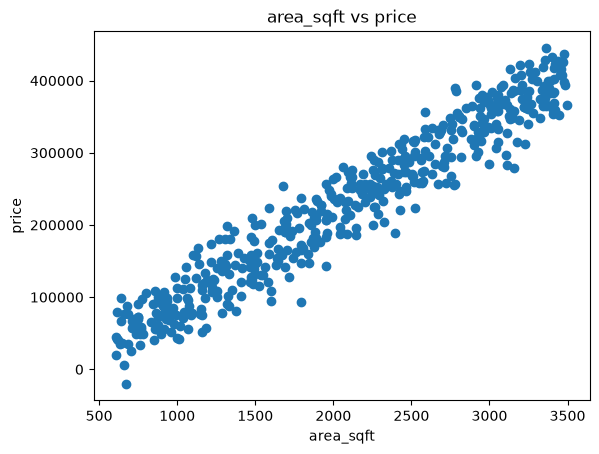

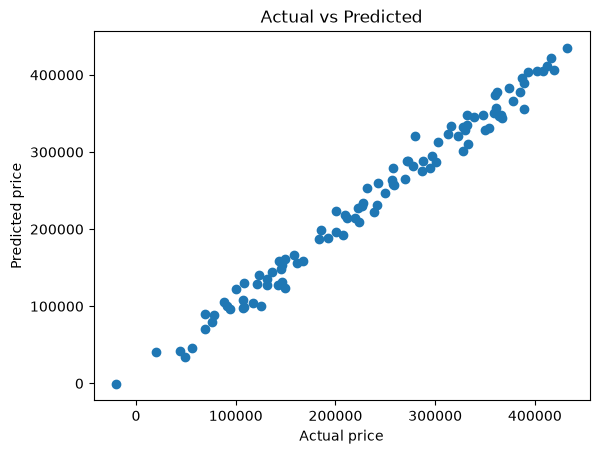

In [7]:
path1 = r"C:\Users\Rauf\Desktop\ann\house_prices.csv"

df1 = load_data(path1)
df1 = clean_data(df1)

features1 = ["area_sqft", "bedrooms", "age_years", "distance_km"]
model1, y1_test, pred1 = train_model(df1, features1, "price")
show_graphs(df1, "area_sqft", "price", y1_test, pred1)

## Dataset 2: Diabetes

    age  sex   bmi     bp     s1     s2    s3   s4      s5    s6  target
0  59.0  2.0  32.1  101.0  157.0   93.2  38.0  4.0  4.8598  87.0   151.0
1  48.0  1.0  21.6   87.0  183.0  103.2  70.0  3.0  3.8918  69.0    75.0
2  72.0  2.0  30.5   93.0  156.0   93.6  41.0  4.0  4.6728  85.0   141.0
3  24.0  1.0  25.3   84.0  198.0  131.4  40.0  5.0  4.8903  89.0   206.0
4  50.0  1.0  23.0  101.0  192.0  125.4  52.0  4.0  4.2905  80.0   135.0
Null values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64
Duplicate rows: 0
R2 score: 0.45691805726470835


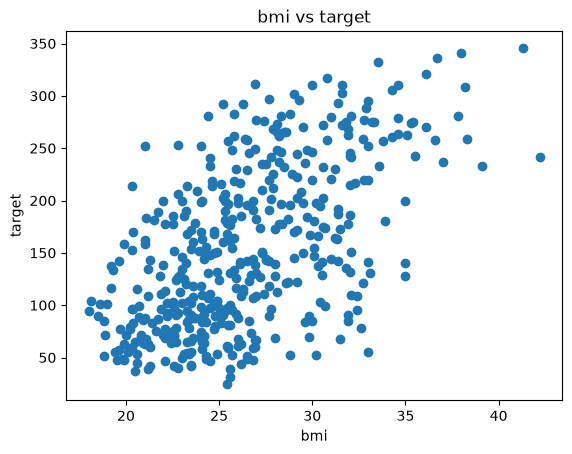

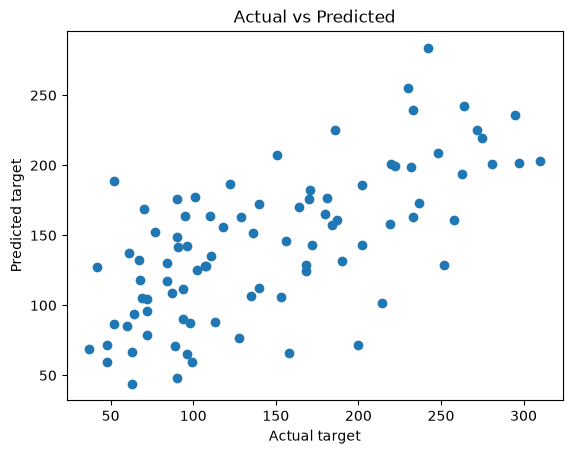

In [8]:
path2 = r"C:\Users\Rauf\Desktop\ann\diabetes.csv"

df2 = load_data(path2)
df2 = clean_data(df2)

features2 = ["age", "bmi", "bp", "s5"]
model2, y2_test, pred2 = train_model(df2, features2, "target")
show_graphs(df2, "bmi", "target", y2_test, pred2)

In [9]:
def predict_house(area, bedrooms, age, distance):
    price = model1.predict([[area, bedrooms, age, distance]])[0]
    return "Predicted price: $" + str(round(price))

In [10]:
def predict_diabetes(age, bmi, bp, s5):
    score = model2.predict([[age, bmi, bp, s5]])[0]
    return "Predicted score: " + str(round(score, 2))

In [11]:
house_ui = gr.Interface(
    fn=predict_house,
    inputs=[gr.Number(label="Area (sq ft)", value=1800),
            gr.Number(label="Bedrooms", value=3),
            gr.Number(label="House age (years)", value=15),
            gr.Number(label="Distance from city (km)", value=10)],
    outputs="text")

diabetes_ui = gr.Interface(
    fn=predict_diabetes,
    inputs=[gr.Number(label="Age", value=50),
            gr.Number(label="BMI", value=26),
            gr.Number(label="Blood pressure", value=95),
            gr.Number(label="s5", value=4.6)],
    outputs="text")

demo = gr.TabbedInterface([house_ui, diabetes_ui], ["House Price", "Diabetes"])
demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


In [12]:
app = Flask(__name__)

page = """
<h1>Linear Regression</h1>

<h2>House Price</h2>
<form method="POST" action="/house">
    <input name="area" placeholder="Area (sq ft)"><br>
    <input name="bedrooms" placeholder="Bedrooms"><br>
    <input name="age" placeholder="House age"><br>
    <input name="distance" placeholder="Distance (km)"><br>
    <button>Predict</button>
</form>

<h2>Diabetes</h2>
<form method="POST" action="/diabetes">
    <input name="age" placeholder="Age"><br>
    <input name="bmi" placeholder="BMI"><br>
    <input name="bp" placeholder="Blood pressure"><br>
    <input name="s5" placeholder="s5 (example 4.6)"><br>
    <button>Predict</button>
</form>

<h2>{{ result }}</h2>
"""

In [13]:
@app.route("/")
def home():
    return render_template_string(page, result="")

In [14]:
@app.route("/house", methods=["POST"])
def house_result():
    a = float(request.form["area"])
    b = float(request.form["bedrooms"])
    c = float(request.form["age"])
    d = float(request.form["distance"])
    price = model1.predict([[a, b, c, d]])[0]
    return render_template_string(page, result="Predicted price: $" + str(round(price)))

In [15]:
@app.route("/diabetes", methods=["POST"])
def diabetes_result():
    a = float(request.form["age"])
    b = float(request.form["bmi"])
    c = float(request.form["bp"])
    d = float(request.form["s5"])
    score = model2.predict([[a, b, c, d]])[0]
    return render_template_string(page, result="Predicted score: " + str(round(score, 2)))

In [17]:
def run_flask():
    app.run(port=5000, use_reloader=False)

Thread(target=run_flask).start()

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [13/Oct/2026 11:05:37] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [13/Oct/2026 11:05:37] "GET /favicon.ico HTTP/1.1" 404 -
